# 08 Hyperparameter Tuning

## Objective

The objective of this notebook is to optimize the Random Forest and XGBoost regression models using RandomizedSearchCV.

The baseline experiments showed that the tree-based models experienced overfitting. Therefore, hyperparameter tuning is performed to identify parameter combinations that improve model generalization and reduce the difference between training and testing performance.

Two feature sets are evaluated:

- Feature Set A: Internship Experience constructs only
- Feature Set B: Internship Experience constructs and demographic variables

The tuned models are evaluated using Test R², MAE, RMSE, five-fold cross-validation performance, and the overfitting gap. Their results are then compared with the baseline Linear Regression model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    train_test_split,
    KFold,
    RandomizedSearchCV,
    cross_val_score
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from xgboost import XGBRegressor

In [2]:
PROJECT_DIR = Path.cwd().parent

DATA_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "descriptive_dataset.csv"
)

df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1000, 29)


,Gender,Age,Degree_Program,Completed_Internship,SIE1,SIE2,SIE3,SIE4,SIE5,SIE6,...,EMP4,EMP5,EMP6,EMP7,EMP8,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Employability_Score
0,Male,24–26,Engineering,Yes,4,5,4,4,5,5,...,4,4,4,5,5,4.25,5.0,4.25,4.5,4.625
1,Male,21–23,Information Technology,Yes,5,4,4,4,4,4,...,4,3,5,4,4,4.25,4.0,3.75,3.5,3.875
2,Male,21–23,Information Technology,Yes,4,5,4,4,4,3,...,4,4,5,4,3,4.25,3.5,4.00,4.0,3.875
3,Female,18–20,Engineering,Yes,4,4,4,4,4,3,...,4,4,4,4,4,4.00,3.5,3.75,3.0,4.000
4,Prefer not to say,18–20,Other,Yes,4,5,4,4,4,5,...,4,5,5,4,4,4.25,4.5,4.25,4.5,4.250


In [3]:
target_column = "Employability_Score"

y = df[target_column].copy()

print("Target shape:", y.shape)
print("Missing target values:", y.isna().sum())

Target shape: (1000,)
Missing target values: 0


In [4]:
features_A = [
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]

X_A = df[features_A].copy()

print("Feature Set A shape:", X_A.shape)
X_A.head()

Feature Set A shape: (1000, 4)


,Clear_Objectives,School_Support,Workplace_Environment,Career_Development
0,4.25,5.0,4.25,4.5
1,4.25,4.0,3.75,3.5
2,4.25,3.5,4.00,4.0
3,4.00,3.5,3.75,3.0
4,4.25,4.5,4.25,4.5


In [5]:
features_B = [
    "Gender",
    "Age",
    "Degree_Program",
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]

X_B = df[features_B].copy()

X_B = pd.get_dummies(
    X_B,
    columns=[
        "Gender",
        "Age",
        "Degree_Program"
    ],
    drop_first=True
)

bool_columns = X_B.select_dtypes(include="bool").columns
X_B[bool_columns] = X_B[bool_columns].astype(int)

print("Feature Set B shape:", X_B.shape)
X_B.head()

Feature Set B shape: (1000, 12)


,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Gender_Male,Gender_Prefer not to say,Age_21–23,Age_24–26,Age_Above 26,Degree_Program_Engineering,Degree_Program_Information Technology,Degree_Program_Other
0,4.25,5.0,4.25,4.5,1,0,0,1,0,1,0,0
1,4.25,4.0,3.75,3.5,1,0,1,0,0,0,1,0
2,4.25,3.5,4.00,4.0,1,0,1,0,0,0,1,0
3,4.00,3.5,3.75,3.0,0,0,0,0,0,1,0,0
4,4.25,4.5,4.25,4.5,0,1,0,0,0,0,0,1


In [6]:
assert X_A.isna().sum().sum() == 0
assert X_B.isna().sum().sum() == 0
assert y.isna().sum() == 0

print("Data validation passed.")

Data validation passed.


In [7]:
train_indices, test_indices = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42
)

X_train_A = X_A.iloc[train_indices]
X_test_A = X_A.iloc[test_indices]

X_train_B = X_B.iloc[train_indices]
X_test_B = X_B.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("Feature Set A:", X_train_A.shape, X_test_A.shape)
print("Feature Set B:", X_train_B.shape, X_test_B.shape)
print("Target:", y_train.shape, y_test.shape)

Feature Set A: (800, 4) (200, 4)
Feature Set B: (800, 12) (200, 12)
Target: (800,) (200,)


In [8]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [9]:
def evaluate_tuned_model(
    model,
    model_name,
    feature_set_name,
    X_train,
    X_test,
    y_train,
    y_test
):
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_r2 = r2_score(y_train, train_predictions)
    test_r2 = r2_score(y_test, test_predictions)

    mae = mean_absolute_error(
        y_test,
        test_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            test_predictions
        )
    )

    overfitting_gap = train_r2 - test_r2

    return {
        "Model": model_name,
        "Feature Set": feature_set_name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "MAE": mae,
        "RMSE": rmse,
        "Overfitting Gap": overfitting_gap
    }

In [10]:
rf_parameter_space = {
    "n_estimators": [
        100,
        200,
        300,
        500,
        700
    ],

    "max_depth": [
        None,
        3,
        5,
        7,
        10,
        15
    ],

    "min_samples_split": [
        2,
        5,
        10,
        15,
        20
    ],

    "min_samples_leaf": [
        1,
        2,
        4,
        6,
        8
    ],

    "max_features": [
        1.0,
        "sqrt",
        "log2"
    ],

    "bootstrap": [
        True,
        False
    ]
}

In [11]:
rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

In [12]:
rf_search_A = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=rf_parameter_space,
    n_iter=30,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

rf_search_A.fit(
    X_train_A,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True, False], 'max_depth': [None, 3, ...], 'max_features': [1.0, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select 

In [13]:
print("Random Forest A - Best Parameters:")
print(rf_search_A.best_params_)

print("\nBest CV R²:")
print(round(rf_search_A.best_score_, 4))

Random Forest A - Best Parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10, 'bootstrap': True}

Best CV R²:
0.5069


In [14]:
best_rf_A = rf_search_A.best_estimator_

rf_result_A = evaluate_tuned_model(
    model=best_rf_A,
    model_name="Tuned Random Forest",
    feature_set_name="A - Internship Constructs",
    X_train=X_train_A,
    X_test=X_test_A,
    y_train=y_train,
    y_test=y_test
)

rf_result_A

{'Model': 'Tuned Random Forest',
 'Feature Set': 'A - Internship Constructs',
 'Train R2': 0.5909226531502628,
 'Test R2': 0.44899770226738445,
 'MAE': 0.17860708028005348,
 'RMSE': np.float64(0.2952009420880695),
 'Overfitting Gap': 0.14192495088287838}

In [15]:
rf_search_B = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=rf_parameter_space,
    n_iter=30,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

rf_search_B.fit(
    X_train_B,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True, False], 'max_depth': [None, 3, ...], 'max_features': [1.0, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select 

In [16]:
print("Random Forest B - Best Parameters:")
print(rf_search_B.best_params_)

print("\nBest CV R²:")
print(round(rf_search_B.best_score_, 4))

Random Forest B - Best Parameters:
{'n_estimators': 300, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15, 'bootstrap': True}

Best CV R²:
0.4895


In [17]:
best_rf_B = rf_search_B.best_estimator_

rf_result_B = evaluate_tuned_model(
    model=best_rf_B,
    model_name="Tuned Random Forest",
    feature_set_name="B - Constructs + Demographics",
    X_train=X_train_B,
    X_test=X_test_B,
    y_train=y_train,
    y_test=y_test
)

rf_result_B

{'Model': 'Tuned Random Forest',
 'Feature Set': 'B - Constructs + Demographics',
 'Train R2': 0.609937795764745,
 'Test R2': 0.41482376719828884,
 'MAE': 0.1873512391721734,
 'RMSE': np.float64(0.304217626430787),
 'Overfitting Gap': 0.1951140285664562}

In [18]:
xgb_parameter_space = {
    "n_estimators": [
        100,
        200,
        300,
        500
    ],

    "learning_rate": [
        0.01,
        0.03,
        0.05,
        0.08,
        0.10
    ],

    "max_depth": [
        2,
        3,
        4,
        5,
        6
    ],

    "min_child_weight": [
        1,
        2,
        4,
        6
    ],

    "subsample": [
        0.60,
        0.70,
        0.80,
        0.90,
        1.00
    ],

    "colsample_bytree": [
        0.60,
        0.70,
        0.80,
        0.90,
        1.00
    ],

    "reg_alpha": [
        0,
        0.01,
        0.10,
        0.50,
        1.00
    ],

    "reg_lambda": [
        0.50,
        1.00,
        2.00,
        5.00,
        10.00
    ]
}

In [19]:
xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

In [20]:
xgb_search_A = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_parameter_space,
    n_iter=30,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

xgb_search_A.fit(
    X_train_A,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.7, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'min_child_weight': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to

In [21]:
print("XGBoost A - Best Parameters:")
print(xgb_search_A.best_params_)

print("\nBest CV R²:")
print(round(xgb_search_A.best_score_, 4))

XGBoost A - Best Parameters:
{'subsample': 0.8, 'reg_lambda': 5.0, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 6, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 1.0}

Best CV R²:
0.5037


In [22]:
best_xgb_A = xgb_search_A.best_estimator_

xgb_result_A = evaluate_tuned_model(
    model=best_xgb_A,
    model_name="Tuned XGBoost",
    feature_set_name="A - Internship Constructs",
    X_train=X_train_A,
    X_test=X_test_A,
    y_train=y_train,
    y_test=y_test
)

xgb_result_A

{'Model': 'Tuned XGBoost',
 'Feature Set': 'A - Internship Constructs',
 'Train R2': 0.633179823184884,
 'Test R2': 0.4804853566419942,
 'MAE': 0.17956455945968627,
 'RMSE': np.float64(0.28664206961288735),
 'Overfitting Gap': 0.15269446654288976}

In [23]:
xgb_search_B = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_parameter_space,
    n_iter=30,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

xgb_search_B.fit(
    X_train_B,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.7, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'min_child_weight': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to

In [24]:
print("XGBoost B - Best Parameters:")
print(xgb_search_B.best_params_)

print("\nBest CV R²:")
print(round(xgb_search_B.best_score_, 4))

XGBoost B - Best Parameters:
{'subsample': 0.7, 'reg_lambda': 2.0, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 4, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.6}

Best CV R²:
0.4891


In [25]:
best_xgb_B = xgb_search_B.best_estimator_

xgb_result_B = evaluate_tuned_model(
    model=best_xgb_B,
    model_name="Tuned XGBoost",
    feature_set_name="B - Constructs + Demographics",
    X_train=X_train_B,
    X_test=X_test_B,
    y_train=y_train,
    y_test=y_test
)

xgb_result_B

{'Model': 'Tuned XGBoost',
 'Feature Set': 'B - Constructs + Demographics',
 'Train R2': 0.6035518264203692,
 'Test R2': 0.44023006903432627,
 'MAE': 0.18660471439361573,
 'RMSE': np.float64(0.2975403140815925),
 'Overfitting Gap': 0.16332175738604293}

In [26]:
tuned_results = pd.DataFrame([
    rf_result_A,
    rf_result_B,
    xgb_result_A,
    xgb_result_B
])

tuned_results = tuned_results.sort_values(
    by="Test R2",
    ascending=False
)

tuned_results.round(4)

,Model,Feature Set,Train R2,Test R2,MAE,RMSE,Overfitting Gap
2,Tuned XGBoost,A - Internship Constructs,0.6332,0.4805,0.1796,0.2866,0.1527
0,Tuned Random Forest,A - Internship Constructs,0.5909,0.4490,0.1786,0.2952,0.1419
3,Tuned XGBoost,B - Constructs + Demographics,0.6036,0.4402,0.1866,0.2975,0.1633
1,Tuned Random Forest,B - Constructs + Demographics,0.6099,0.4148,0.1874,0.3042,0.1951


In [27]:
cv_scores = {
    (
        "Tuned Random Forest",
        "A - Internship Constructs"
    ): rf_search_A.best_score_,

    (
        "Tuned Random Forest",
        "B - Constructs + Demographics"
    ): rf_search_B.best_score_,

    (
        "Tuned XGBoost",
        "A - Internship Constructs"
    ): xgb_search_A.best_score_,

    (
        "Tuned XGBoost",
        "B - Constructs + Demographics"
    ): xgb_search_B.best_score_
}

In [28]:
tuned_results["CV R2 Mean"] = tuned_results.apply(
    lambda row: cv_scores[
        (
            row["Model"],
            row["Feature Set"]
        )
    ],
    axis=1
)

tuned_results.round(4)

,Model,Feature Set,Train R2,Test R2,MAE,RMSE,Overfitting Gap,CV R2 Mean
2,Tuned XGBoost,A - Internship Constructs,0.6332,0.4805,0.1796,0.2866,0.1527,0.5037
0,Tuned Random Forest,A - Internship Constructs,0.5909,0.4490,0.1786,0.2952,0.1419,0.5069
3,Tuned XGBoost,B - Constructs + Demographics,0.6036,0.4402,0.1866,0.2975,0.1633,0.4891
1,Tuned Random Forest,B - Constructs + Demographics,0.6099,0.4148,0.1874,0.3042,0.1951,0.4895


In [29]:
def interpret_overfitting(gap):
    if gap <= 0.05:
        return "Low"

    if gap <= 0.15:
        return "Moderate"

    return "High"


tuned_results["Overfitting Risk"] = (
    tuned_results["Overfitting Gap"]
    .apply(interpret_overfitting)
)

tuned_results.round(4)

,Model,Feature Set,Train R2,Test R2,MAE,RMSE,Overfitting Gap,CV R2 Mean,Overfitting Risk
2,Tuned XGBoost,A - Internship Constructs,0.6332,0.4805,0.1796,0.2866,0.1527,0.5037,High
0,Tuned Random Forest,A - Internship Constructs,0.5909,0.4490,0.1786,0.2952,0.1419,0.5069,Moderate
3,Tuned XGBoost,B - Constructs + Demographics,0.6036,0.4402,0.1866,0.2975,0.1633,0.4891,High
1,Tuned Random Forest,B - Constructs + Demographics,0.6099,0.4148,0.1874,0.3042,0.1951,0.4895,High


In [30]:
baseline_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Feature Set": "A - Internship Constructs",
        "Test R2": 0.4428,
        "MAE": 0.1907,
        "RMSE": 0.2969,
        "CV R2 Mean": 0.4589,
        "Overfitting Gap": 0.0391
    },
    {
        "Model": "Linear Regression",
        "Feature Set": "B - Constructs + Demographics",
        "Test R2": 0.4432,
        "MAE": 0.1920,
        "RMSE": 0.2968,
        "CV R2 Mean": 0.4549,
        "Overfitting Gap": 0.0438
    },
    {
        "Model": "Baseline Random Forest",
        "Feature Set": "A - Internship Constructs",
        "Test R2": 0.4189,
        "MAE": 0.1816,
        "RMSE": 0.3032,
        "CV R2 Mean": 0.4061,
        "Overfitting Gap": 0.3211
    },
    {
        "Model": "Baseline Random Forest",
        "Feature Set": "B - Constructs + Demographics",
        "Test R2": 0.3766,
        "MAE": 0.1966,
        "RMSE": 0.3140,
        "CV R2 Mean": 0.3907,
        "Overfitting Gap": 0.4577
    },
    {
        "Model": "Baseline XGBoost",
        "Feature Set": "A - Internship Constructs",
        "Test R2": 0.4056,
        "MAE": 0.1843,
        "RMSE": 0.3066,
        "CV R2 Mean": 0.4372,
        "Overfitting Gap": 0.2907
    },
    {
        "Model": "Baseline XGBoost",
        "Feature Set": "B - Constructs + Demographics",
        "Test R2": 0.4351,
        "MAE": 0.1831,
        "RMSE": 0.2989,
        "CV R2 Mean": 0.4076,
        "Overfitting Gap": 0.2866
    }
])

In [31]:
final_comparison = pd.concat(
    [
        baseline_results,
        tuned_results
    ],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by=[
        "CV R2 Mean",
        "Test R2"
    ],
    ascending=False
)

final_comparison.round(4)

,Model,Feature Set,Test R2,MAE,RMSE,CV R2 Mean,Overfitting Gap,Train R2,Overfitting Risk
7,Tuned Random Forest,A - Internship Constructs,0.4490,0.1786,0.2952,0.5069,0.1419,0.5909,Moderate
6,Tuned XGBoost,A - Internship Constructs,0.4805,0.1796,0.2866,0.5037,0.1527,0.6332,High
9,Tuned Random Forest,B - Constructs + Demographics,0.4148,0.1874,0.3042,0.4895,0.1951,0.6099,High
8,Tuned XGBoost,B - Constructs + Demographics,0.4402,0.1866,0.2975,0.4891,0.1633,0.6036,High
0,Linear Regression,A - Internship Constructs,0.4428,0.1907,0.2969,0.4589,0.0391,NaN,NaN
1,Linear Regression,B - Constructs + Demographics,0.4432,0.1920,0.2968,0.4549,0.0438,NaN,NaN
4,Baseline XGBoost,A - Internship Constructs,0.4056,0.1843,0.3066,0.4372,0.2907,NaN,NaN
5,Baseline XGBoost,B - Constructs + Demographics,0.4351,0.1831,0.2989,0.4076,0.2866,NaN,NaN
2,Baseline Random Forest,A - Internship Constructs,0.4189,0.1816,0.3032,0.4061,0.3211,NaN,NaN
3,Baseline Random Forest,B - Constructs + Demographics,0.3766,0.1966,0.3140,0.3907,0.4577,NaN,NaN


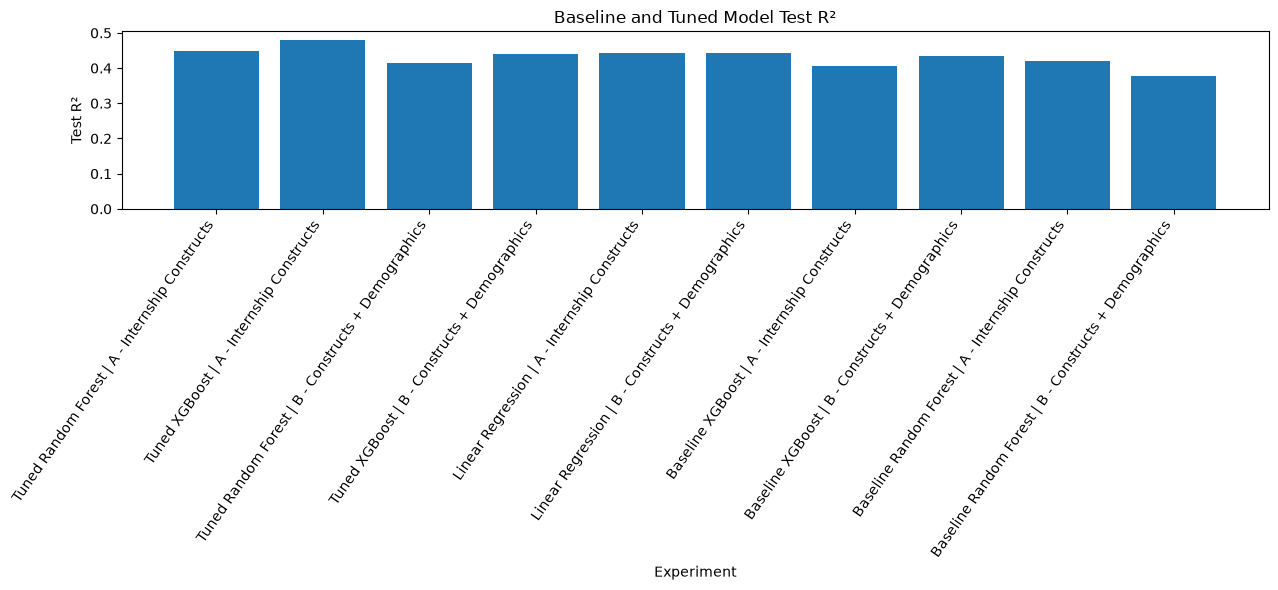

In [32]:
plot_df = final_comparison.copy()

plot_df["Experiment"] = (
    plot_df["Model"]
    + " | "
    + plot_df["Feature Set"]
)

plt.figure(figsize=(13, 6))

plt.bar(
    plot_df["Experiment"],
    plot_df["Test R2"]
)

plt.title("Baseline and Tuned Model Test R²")
plt.xlabel("Experiment")
plt.ylabel("Test R²")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

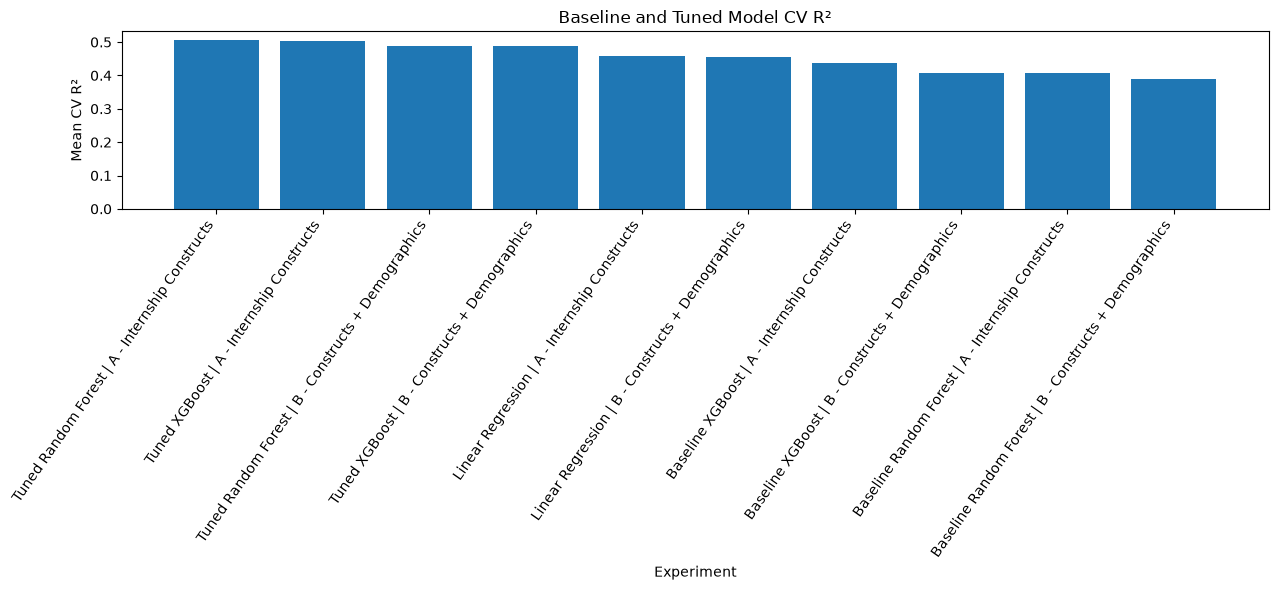

In [33]:
plt.figure(figsize=(13, 6))

plt.bar(
    plot_df["Experiment"],
    plot_df["CV R2 Mean"]
)

plt.title("Baseline and Tuned Model CV R²")
plt.xlabel("Experiment")
plt.ylabel("Mean CV R²")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

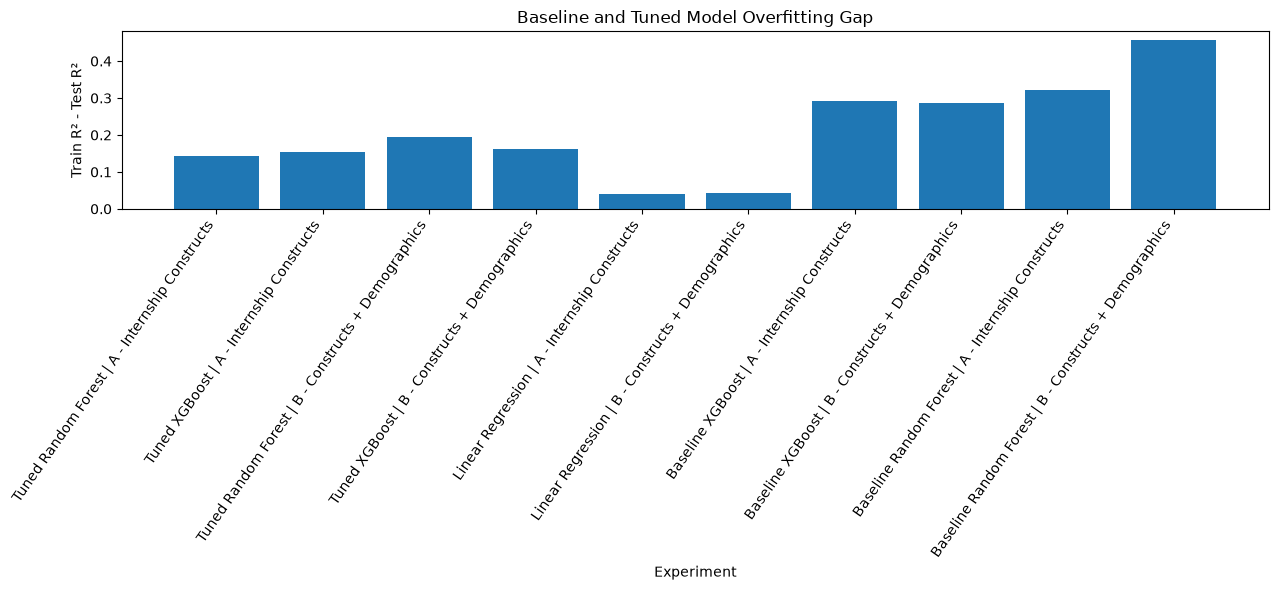

In [34]:
plt.figure(figsize=(13, 6))

plt.bar(
    plot_df["Experiment"],
    plot_df["Overfitting Gap"]
)

plt.title("Baseline and Tuned Model Overfitting Gap")
plt.xlabel("Experiment")
plt.ylabel("Train R² - Test R²")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

In [35]:
best_candidate = final_comparison.iloc[0]

print("Best candidate:")
print("Model:", best_candidate["Model"])
print("Feature Set:", best_candidate["Feature Set"])
print("Test R²:", round(best_candidate["Test R2"], 4))
print("CV R²:", round(best_candidate["CV R2 Mean"], 4))
print("MAE:", round(best_candidate["MAE"], 4))
print("RMSE:", round(best_candidate["RMSE"], 4))
print(
    "Overfitting Gap:",
    round(best_candidate["Overfitting Gap"], 4)
)

Best candidate:
Model: Tuned Random Forest
Feature Set: A - Internship Constructs
Test R²: 0.449
CV R²: 0.5069
MAE: 0.1786
RMSE: 0.2952
Overfitting Gap: 0.1419


In [36]:
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

tuned_results.to_csv(
    REPORT_DIR / "Tuned_Model_Results.csv",
    index=False
)

final_comparison.to_csv(
    REPORT_DIR / "Baseline_vs_Tuned_Models.csv",
    index=False
)

In [37]:
best_parameters = pd.DataFrame([
    {
        "Experiment": "Random Forest A",
        "Best Parameters": str(
            rf_search_A.best_params_
        ),
        "Best CV R2": rf_search_A.best_score_
    },
    {
        "Experiment": "Random Forest B",
        "Best Parameters": str(
            rf_search_B.best_params_
        ),
        "Best CV R2": rf_search_B.best_score_
    },
    {
        "Experiment": "XGBoost A",
        "Best Parameters": str(
            xgb_search_A.best_params_
        ),
        "Best CV R2": xgb_search_A.best_score_
    },
    {
        "Experiment": "XGBoost B",
        "Best Parameters": str(
            xgb_search_B.best_params_
        ),
        "Best CV R2": xgb_search_B.best_score_
    }
])

best_parameters.to_csv(
    REPORT_DIR / "Best_Hyperparameters.csv",
    index=False
)

best_parameters

,Experiment,Best Parameters,Best CV R2
0,Random Forest A,"{'n_estimators': 100, 'min_samples_split': 10,...",0.506927
1,Random Forest B,"{'n_estimators': 300, 'min_samples_split': 20,...",0.489469
2,XGBoost A,"{'subsample': 0.8, 'reg_lambda': 5.0, 'reg_alp...",0.503740
3,XGBoost B,"{'subsample': 0.7, 'reg_lambda': 2.0, 'reg_alp...",0.489137


## Hyperparameter Tuning Method

RandomizedSearchCV was used to optimize the Random Forest and XGBoost regression models. Randomized search was selected because it efficiently evaluates a broad range of parameter combinations without the computational cost of testing every possible combination.

Thirty parameter combinations were evaluated for each model and feature set using five-fold cross-validation. R² was used as the optimization metric because the target was a continuous Employability Score.

Hyperparameter tuning was conducted using only the training data. The untouched testing set was used once after tuning to estimate final generalization performance and prevent test-data leakage.

## Interpretation of Hyperparameter Tuning

Hyperparameter tuning was performed to determine whether the performance and generalization of the tree-based ensemble models could be improved.

The tuned Random Forest and XGBoost models were compared with their baseline configurations and the Linear Regression baseline using Test R², MAE, RMSE, cross-validation R², and overfitting gap.

The final model was selected based on overall predictive performance, cross-validation stability, generalization ability, and model interpretability rather than relying on a single evaluation metric.

2. Fix the “best candidate” selection

In [38]:
ranking_df = final_comparison.copy()

ranking_df["Rank_Test_R2"] = ranking_df["Test R2"].rank(
    ascending=False,
    method="min"
)

ranking_df["Rank_CV_R2"] = ranking_df["CV R2 Mean"].rank(
    ascending=False,
    method="min"
)

ranking_df["Rank_MAE"] = ranking_df["MAE"].rank(
    ascending=True,
    method="min"
)

ranking_df["Rank_RMSE"] = ranking_df["RMSE"].rank(
    ascending=True,
    method="min"
)

ranking_df["Rank_Overfitting"] = ranking_df[
    "Overfitting Gap"
].rank(
    ascending=True,
    method="min"
)

ranking_df["Average_Rank"] = ranking_df[
    [
        "Rank_Test_R2",
        "Rank_CV_R2",
        "Rank_MAE",
        "Rank_RMSE",
        "Rank_Overfitting"
    ]
].mean(axis=1)

ranking_df = ranking_df.sort_values("Average_Rank")

ranking_df[
    [
        "Model",
        "Feature Set",
        "Test R2",
        "CV R2 Mean",
        "MAE",
        "RMSE",
        "Overfitting Gap",
        "Average_Rank"
    ]
].round(4)

,Model,Feature Set,Test R2,CV R2 Mean,MAE,RMSE,Overfitting Gap,Average_Rank
7,Tuned Random Forest,A - Internship Constructs,0.4490,0.5069,0.1786,0.2952,0.1419,1.8
6,Tuned XGBoost,A - Internship Constructs,0.4805,0.5037,0.1796,0.2866,0.1527,2.0
0,Linear Regression,A - Internship Constructs,0.4428,0.4589,0.1907,0.2969,0.0391,4.4
1,Linear Regression,B - Constructs + Demographics,0.4432,0.4549,0.1920,0.2968,0.0438,4.6
8,Tuned XGBoost,B - Constructs + Demographics,0.4402,0.4891,0.1866,0.2975,0.1633,5.0
5,Baseline XGBoost,B - Constructs + Demographics,0.4351,0.4076,0.1831,0.2989,0.2866,6.2
9,Tuned Random Forest,B - Constructs + Demographics,0.4148,0.4895,0.1874,0.3042,0.1951,6.4
2,Baseline Random Forest,A - Internship Constructs,0.4189,0.4061,0.1816,0.3032,0.3211,7.0
4,Baseline XGBoost,A - Internship Constructs,0.4056,0.4372,0.1843,0.3066,0.2907,7.6
3,Baseline Random Forest,B - Constructs + Demographics,0.3766,0.3907,0.1966,0.3140,0.4577,10.0


1. Overfitting interpretation update

In [39]:
def interpret_overfitting(gap):
    if gap <= 0.05:
        return "Low"
    elif gap <= 0.15:
        return "Moderate"
    elif gap <= 0.30:
        return "High"
    else:
        return "Very High"

In [40]:
tuned_results["Overfitting Risk"] = (
    tuned_results["Overfitting Gap"]
    .apply(interpret_overfitting)
)

tuned_results.round(4)

,Model,Feature Set,Train R2,Test R2,MAE,RMSE,Overfitting Gap,CV R2 Mean,Overfitting Risk
2,Tuned XGBoost,A - Internship Constructs,0.6332,0.4805,0.1796,0.2866,0.1527,0.5037,High
0,Tuned Random Forest,A - Internship Constructs,0.5909,0.4490,0.1786,0.2952,0.1419,0.5069,Moderate
3,Tuned XGBoost,B - Constructs + Demographics,0.6036,0.4402,0.1866,0.2975,0.1633,0.4891,High
1,Tuned Random Forest,B - Constructs + Demographics,0.6099,0.4148,0.1874,0.3042,0.1951,0.4895,High


In [41]:
from sklearn.model_selection import RepeatedKFold, cross_validate

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

candidate_models = {
    "Tuned Random Forest A": best_rf_A,
    "Tuned XGBoost A": best_xgb_A
}

repeated_results = []

for name, model in candidate_models.items():
    scores = cross_validate(
        model,
        X_A,
        y,
        cv=repeated_cv,
        scoring=scoring,
        n_jobs=-1
    )

    repeated_results.append({
        "Model": name,
        "Mean R2": scores["test_r2"].mean(),
        "R2 Std": scores["test_r2"].std(),
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean()
    })

repeated_results_df = pd.DataFrame(repeated_results)

repeated_results_df.round(4)

,Model,Mean R2,R2 Std,Mean MAE,Mean RMSE
0,Tuned Random Forest A,0.4824,0.0788,0.1673,0.2642
1,Tuned XGBoost A,0.4814,0.0807,0.1673,0.2643
